# IND320 Compulsory Assignment 3

## Name: Vasilii Anderson

## Project Links

**GitHub repository:**  
https://github.com/VasiliiAnderson/ind320-project

**Streamlit application:**  
https://vasilii-ind320.streamlit.app/

## 1. Setup and Imports

In [59]:
# Import libraries used for file handling, geospatial processing,
# API requests, visualisation and statistical/time-series analysis.

from pathlib import Path
import time

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

from scipy.fft import dct, idct
from scipy.signal import spectrogram
from scipy.stats import median_abs_deviation
from sklearn.neighbors import LocalOutlierFactor
from statsmodels.tsa.seasonal import STL


# Define the project root in a portable way so the notebook does not
# depend on an absolute path specific to this computer.
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"

print("Project root:", PROJECT_ROOT)

Project root: c:\dev\IND320\project


## 2. Geographical Areas and Random Locations

NVE shapefiles are used to define the geographical areas required for the weather analysis. Two geographical classifications are relevant: the precipitation/reservoir regions used by Magasinstatistikk and the electricity bidding areas NO1 - NO5.

### 2.1 NVE Regions

The NVE regional shapefile contains five administrative regions. To correspond with the three VASS areas in Magasinstatistikk, the eastern regions RS and RØ are combined, while RM and RN are combined for the northern area. RV represents the western area.

In [62]:
# Load the NVE regional shapefile and inspect the available regions.

nve_region_path = (
    DATA_DIR
    / "shapefiles"
    / "nve_regions"
    / "NVE_Region.shp"
)

nve_regions = gpd.read_file(nve_region_path)

print("CRS:", nve_regions.crs)
print("NVE regions:", nve_regions["REGION"].unique())

display(nve_regions.head())

CRS: EPSG:25833
NVE regions: <ArrowStringArray>
['RV', 'RM', 'RN', 'RÃ', 'RS']
Length: 5, dtype: str


,OBJECTID,REGION,REGIONNAVN,POSTNUMMER,POSTSTED,BESÃKSADR,ADRESSE,geometry
0,1.0,RV,Region Vest,6801,FÃ¸rde,Naustdalsveien 1B,Postboks 53,"POLYGON ((193105.76 6929797.839, 191705.75 692..."
1,2.0,RM,Region Midt-Norge,7030,Trondheim,"Abelsgate 9, Trondheim",Abelsgate 9,"POLYGON ((391250 7388620, 392270 7386790, 3937..."
2,3.0,RN,Region Nord,8514,Narvik,Kongensgate 52-54,Kongensgate 52-54,"POLYGON ((1109096.413 7844647.502, 1105115.343..."
3,4.0,RÃ,Region Ãst,2307,Hamar,Vangsvegen 73,Postboks 4223,"POLYGON ((253748.22 6678130.91, 253645.58 6678..."
4,5.0,RS,Region SÃ¸r,3103,TÃ¸nsberg,Anton Jenssens gate 7,Postboks 2124,"POLYGON ((253748.22 6678130.91, 253917.63 6677..."


c:\dev\IND320\project\.venv\Lib\site-packages\geopandas\plotting.py:1339: UserWarning: Glyph 152 (\x98) missing from font(s) DejaVu Sans.
  ax.figure.canvas.draw_idle()
c:\dev\IND320\project\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 152 (\x98) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


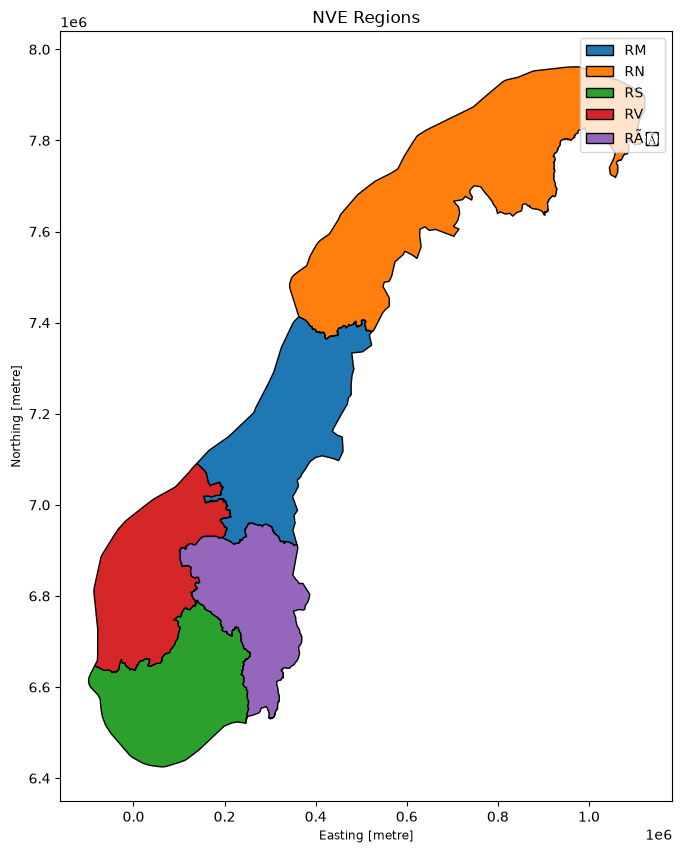

In [63]:
# Visualise the original NVE regions to verify that the
# shapefile has been loaded correctly.

nve_regions.plot(
    column="REGION",
    legend=True,
    figsize=(8, 10),
    edgecolor="black",
)

plt.title("NVE Regions")
plt.show()

The map confirms that the five NVE regional polygons have been loaded correctly. These regions can now be combined to match the three VASS areas used in Magasinstatistikk.

### 2.2 VASS Areas and Random Locations

The NVE regions are combined into the three VASS areas used by Magasinstatistikk:

- VASS1 consists of RS and RØ.
- VASS2 consists of RV.
- VASS3 consists of RM and RN.

For each resulting area, 1000 random locations are sampled. A fixed random seed is used to make the locations reproducible.

In [64]:
# Define the relationship between Magasinstatistikk VASS areas
# and the original NVE regional polygons.

vass_mapping = {
    1: ["RS", "RØ"],
    2: ["RV"],
    3: ["RM", "RN"],
}

vass_rows = []

for area_number, region_codes in vass_mapping.items():

    # Combine all NVE polygons belonging to the VASS area.
    geometry = (
        nve_regions[
            nve_regions["REGION"].isin(region_codes)
        ]
        .geometry
        .union_all()
    )

    vass_rows.append(
        {
            "region": f"VASS{area_number}",
            "geometry": geometry,
        }
    )

vass_gdf = gpd.GeoDataFrame(
    vass_rows,
    crs=nve_regions.crs,
)

display(vass_gdf)

,region,geometry
0,VASS1,"POLYGON ((253748.22 6678130.91, 253917.63 6677..."
1,VASS2,"POLYGON ((193105.76 6929797.839, 191705.75 692..."
2,VASS3,"POLYGON ((522969.98 7381455.32, 520050.96 7378..."


In [65]:
# Randomly sample 1000 locations inside each VASS area.

K = 1000

vass_points = vass_gdf["geometry"].sample_points(
    size=K,
    random_state=42,
)

# Open-Meteo requires latitude and longitude in WGS84.
vass_points_wgs84 = vass_points.to_crs(epsg=4326)

In [66]:
# Extract the sampled VASS locations into a regular DataFrame
# containing region, latitude and longitude.

coordinates_vass = []

for idx, multipoint in vass_points_wgs84.items():

    region_name = vass_gdf.loc[idx, "region"]

    for point in multipoint.geoms:
        coordinates_vass.append(
            {
                "region": region_name,
                "latitude": point.y,
                "longitude": point.x,
            }
        )

coordinates_vass_df = pd.DataFrame(
    coordinates_vass
)

display(coordinates_vass_df.head())

print(
    coordinates_vass_df["region"]
    .value_counts()
)

,region,latitude,longitude
0,VASS1,60.729560,9.020505
1,VASS1,58.745548,9.644737
2,VASS1,58.272036,6.503622
3,VASS1,59.622116,7.016919
4,VASS1,58.080202,7.113234


region
VASS1    1000
VASS2    1000
VASS3    1000
Name: count, dtype: int64


### 2.3 Electricity Bidding Areas

The electricity bidding-area shapefile contains the five Norwegian electricity areas. The original labels contain spaces, such as "NO 3", so the identifiers are standardised to NO1–NO5 before further processing.

In [67]:
# Load the NVE electricity bidding-area shapefile.

elspot_path = (
    DATA_DIR
    / "shapefiles"
    / "elspot"
    / "Budområder.shp"
)

elspot_gdf = gpd.read_file(
    elspot_path
)

# Standardise labels such as "NO 3" to "NO3".
elspot_gdf["region"] = (
    elspot_gdf["budomr"]
    .astype(str)
    .str.replace(" ", "", regex=False)
)

print("CRS:", elspot_gdf.crs)
print(
    "Electricity areas:",
    elspot_gdf["region"].unique(),
)

display(elspot_gdf.head())

CRS: EPSG:25833
Electricity areas: <ArrowStringArray>
['NO1', 'NO2', 'NO3', 'NO4', 'NO5']
Length: 5, dtype: str


,objectid,budomr,globalid,st_area(sh,st_perimet,geometry,region
0,1.0,NO 1,NaN,6.052902e+10,1.657761e+06,"POLYGON ((337473.63 6970542.97, 337711.9 69703...",NO1
1,2.0,NO 2,NaN,6.875969e+10,1.256473e+06,"POLYGON ((-9833.91 6726499.86, -9836 6726404.0...",NO2
2,3.0,NO 3,NaN,1.042199e+11,1.773323e+06,"POLYGON ((308588.7 7261519.43, 313576.63 72590...",NO3
3,4.0,NO 4,NaN,2.032500e+11,3.385499e+06,"POLYGON ((973920.93 7962739.19, 974922.77 7962...",NO4
4,5.0,NO 5,NaN,3.334870e+10,1.106762e+06,"POLYGON ((101466.43 6881318.54, 101525.43 6881...",NO5


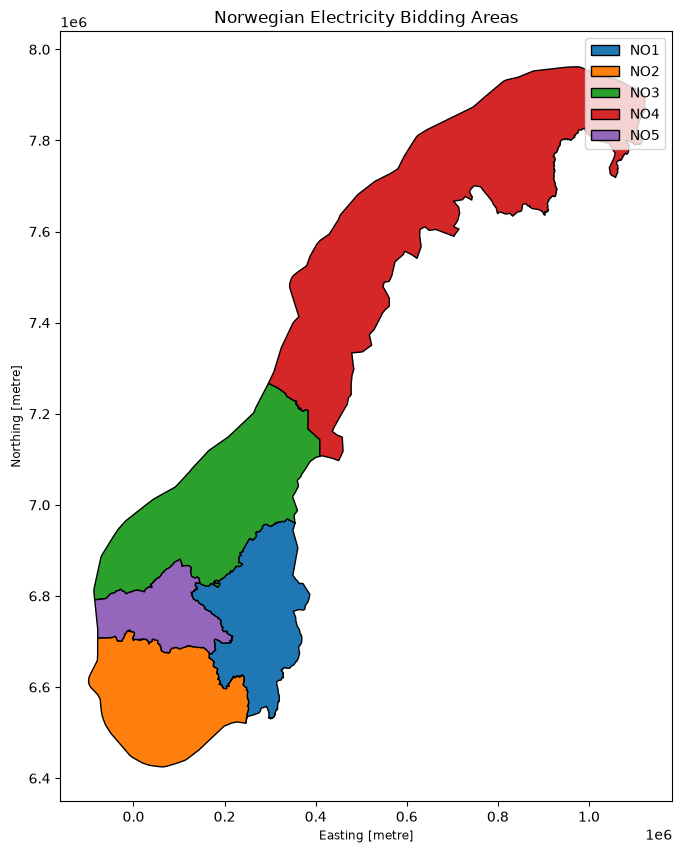

In [69]:
# Visualise the five electricity bidding areas before sampling points.

elspot_gdf.plot(
    column="region",
    legend=True,
    figsize=(8, 10),
    edgecolor="black",
)

plt.title("Norwegian Electricity Bidding Areas")
plt.show()

The map shows the five Norwegian electricity bidding areas NO1–NO5. These polygons are used to ensure that the sampled weather locations correspond geographically to the selected electricity area.

### 2.4 Random Locations in Electricity Areas

As for the VASS regions, 1000 random locations are sampled inside each electricity bidding area. The sampled geometries are converted to WGS84 latitude and longitude for use with Open-Meteo.

In [68]:
# Sample 1000 reproducible locations inside each electricity area.

K = 1000

elspot_points = (
    elspot_gdf["geometry"]
    .sample_points(
        size=K,
        random_state=42,
    )
)

elspot_points_wgs84 = (
    elspot_points
    .to_crs(epsg=4326)
)

In [70]:
# Convert the sampled electricity-area points into a DataFrame.

coordinates_elspot = []

for idx, multipoint in elspot_points_wgs84.items():

    region_name = elspot_gdf.loc[
        idx,
        "region",
    ]

    for point in multipoint.geoms:
        coordinates_elspot.append(
            {
                "region": region_name,
                "latitude": point.y,
                "longitude": point.x,
            }
        )

coordinates_elspot_df = pd.DataFrame(
    coordinates_elspot
)

display(coordinates_elspot_df.head())

print(
    coordinates_elspot_df["region"]
    .value_counts()
)

,region,latitude,longitude
0,NO1,59.870045,10.650058
1,NO1,58.941640,11.556179
2,NO1,60.602637,10.696825
3,NO1,60.313334,11.570452
4,NO1,59.623465,10.478553


region
NO1    1000
NO2    1000
NO3    1000
NO4    1000
NO5    1000
Name: count, dtype: int64


### 2.5 NO3 Coordinates

The assignment specifically requires historical ERA5 weather data for NO3 during 2024. The 1000 sampled NO3 locations are therefore extracted for the following weather analysis.

In [71]:
# Extract the 1000 sampled locations belonging to NO3.

no3_coordinates = (
    coordinates_elspot_df[
        coordinates_elspot_df["region"]
        == "NO3"
    ]
    .reset_index(drop=True)
)

display(no3_coordinates.head())

print(
    "Number of NO3 locations:",
    len(no3_coordinates),
)

,region,latitude,longitude
0,NO3,63.415072,9.342346
1,NO3,61.769699,8.878191
2,NO3,62.907675,10.476492
3,NO3,62.878862,11.100635
4,NO3,62.757399,11.410371


Number of NO3 locations: 1000


## 3. Open-Meteo ERA5 Weather Data

Historical hourly weather data are retrieved through the Open-Meteo Historical Weather API using the ERA5 reanalysis model. Temperature, precipitation and snowfall are included.

Before downloading the complete 2024 dataset, the API connection is tested using one sampled NO3 location and a short three-day interval.

### 3.1 Test API Connection

In [72]:
# Test the Open-Meteo API using one NO3 location and three days
# before requesting the complete weather dataset.

ARCHIVE_URL = (
    "https://archive-api.open-meteo.com/"
    "v1/archive"
)

test_point = no3_coordinates.iloc[0]

params = {
    "latitude": test_point["latitude"],
    "longitude": test_point["longitude"],
    "start_date": "2024-01-01",
    "end_date": "2024-01-03",
    "hourly": (
        "temperature_2m,"
        "precipitation,"
        "snowfall"
    ),
    "models": "era5",
    "timezone": "UTC",
}

response = requests.get(
    ARCHIVE_URL,
    params=params,
    timeout=60,
)

response.raise_for_status()

data = response.json()

weather_test = pd.DataFrame(
    data["hourly"]
)

weather_test["time"] = pd.to_datetime(
    weather_test["time"]
)

print(
    "HTTP status:",
    response.status_code,
)

print(
    "Returned observations:",
    weather_test.shape,
)

display(weather_test.head())

HTTP status: 200
Returned observations: (72, 4)


,time,temperature_2m,precipitation,snowfall
0,2024-01-01 00:00:00,-3.8,0.0,0.0
1,2024-01-01 01:00:00,-4.0,0.0,0.0
2,2024-01-01 02:00:00,-3.9,0.0,0.0
3,2024-01-01 03:00:00,-3.9,0.0,0.0
4,2024-01-01 04:00:00,-3.9,0.0,0.0


The API returned 72 hourly observations for the three-day test interval, confirming that the ERA5 request and selected weather variables were retrieved successfully.

### 3.2 Weather Download Function

The weather download is wrapped in a reusable function. The function receives a region identifier and time interval, selects reproducible locations from the corresponding coordinate set, and downloads hourly ERA5 observations for each selected location.

Ten locations are used in the analysis to keep the number of API requests and the resulting dataset manageable while still representing different parts of NO3.

In [74]:
# Combine the electricity and VASS coordinate sets so that the
# download function can look up locations from a region identifier.

weather_coordinates_df = pd.concat(
    [
        coordinates_elspot_df,
        coordinates_vass_df,
    ],
    ignore_index=True,
)


WEATHER_VARIABLES = [
    "temperature_2m",
    "precipitation",
    "snowfall",
]


def download_weather(
    region,
    start_date,
    end_date,
    n_locations=10,
    random_state=42,
):
    """
    Download hourly ERA5 weather data for sampled locations.

    Parameters
    ----------
    region : str
        Region identifier, for example "NO3".
    start_date : str
        Start date in YYYY-MM-DD format.
    end_date : str
        End date in YYYY-MM-DD format.
    n_locations : int
        Number of sampled locations used.
    random_state : int
        Seed used for reproducible selection.

    Returns
    -------
    pd.DataFrame
        Hourly observations for all selected locations.
    """

    # Find the 1000 coordinates belonging to the requested region.
    region_points = weather_coordinates_df[
        weather_coordinates_df["region"]
        == region
    ]

    if region_points.empty:
        raise ValueError(
            f"No coordinates found for {region}"
        )

    # Select a reproducible subset of locations.
    selected_points = region_points.sample(
        n=min(
            n_locations,
            len(region_points),
        ),
        random_state=random_state,
    )

    weather_frames = []

    for location_id, (_, point) in enumerate(
        selected_points.iterrows()
    ):

        params = {
            "latitude": point["latitude"],
            "longitude": point["longitude"],
            "start_date": start_date,
            "end_date": end_date,
            "hourly": ",".join(
                WEATHER_VARIABLES
            ),
            "models": "era5",
            "timezone": "UTC",
        }

        response = requests.get(
            ARCHIVE_URL,
            params=params,
            timeout=120,
        )

        response.raise_for_status()

        data = response.json()

        hourly = pd.DataFrame(
            data["hourly"]
        )

        hourly["time"] = pd.to_datetime(
            hourly["time"]
        )

        hourly["location_id"] = (
            location_id
        )

        hourly["latitude"] = (
            point["latitude"]
        )

        hourly["longitude"] = (
            point["longitude"]
        )

        weather_frames.append(hourly)

        # Avoid sending requests too rapidly.
        time.sleep(0.2)

    return pd.concat(
        weather_frames,
        ignore_index=True,
    )

### 3.3 NO3 Weather Data for 2024

The function is applied to NO3 for the complete year 2024. Ten locations are reproducibly selected from the 1000 sampled NO3 coordinates.

In [75]:
# Download hourly ERA5 weather observations for NO3 during 2024.

weather_no3_2024 = download_weather(
    region="NO3",
    start_date="2024-01-01",
    end_date="2024-12-31",
    n_locations=10,
)

print(
    "Rows:",
    len(weather_no3_2024),
)

print(
    "Locations:",
    weather_no3_2024[
        "location_id"
    ].nunique(),
)

display(
    weather_no3_2024.head()
)

Rows: 87840
Locations: 10


,time,temperature_2m,precipitation,snowfall,location_id,latitude,longitude
0,2024-01-01 00:00:00,-3.2,0.0,0.0,0,63.795254,9.737149
1,2024-01-01 01:00:00,-3.2,0.0,0.0,0,63.795254,9.737149
2,2024-01-01 02:00:00,-3.2,0.0,0.0,0,63.795254,9.737149
3,2024-01-01 03:00:00,-3.1,0.0,0.0,0,63.795254,9.737149
4,2024-01-01 04:00:00,-2.9,0.0,0.0,0,63.795254,9.737149


### 3.4 Regional Hourly Averages

The weather observations from the ten sampled locations are averaged for each hour. This produces one regional NO3 time series for temperature, precipitation and snowfall.

In [76]:
# Calculate regional hourly averages across the ten sampled locations.

weather_no3_hourly = (
    weather_no3_2024
    .groupby(
        "time",
        as_index=False,
    )
    .agg(
        {
            "temperature_2m": "mean",
            "precipitation": "mean",
            "snowfall": "mean",
        }
    )
    .rename(
        columns={
            "temperature_2m": (
                "avg_temperature"
            ),
            "precipitation": (
                "avg_precipitation"
            ),
            "snowfall": (
                "avg_snowfall"
            ),
        }
    )
)

print(
    "Regional hourly observations:",
    weather_no3_hourly.shape,
)

display(
    weather_no3_hourly.head()
)

Regional hourly observations: (8784, 4)


,time,avg_temperature,avg_precipitation,avg_snowfall
0,2024-01-01 00:00:00,-5.43,0.0,0.0
1,2024-01-01 01:00:00,-5.51,0.0,0.0
2,2024-01-01 02:00:00,-5.49,0.0,0.0
3,2024-01-01 03:00:00,-5.48,0.0,0.0
4,2024-01-01 04:00:00,-5.42,0.0,0.0


## 4. Precipitation Outliers – DCT and Statistical Process Control

The regional average precipitation is analysed for unusual observations. A Discrete Cosine Transform is used to separate slow variations from higher-frequency deviations. The high-pass-filtered series is used internally to identify outliers, while only the original precipitation values and SPC boundaries are displayed.

### 4.1 Precipitation Time Series

In [77]:
# Extract the regional average precipitation series used
# for the DCT and SPC analysis.

precip_series = (
    weather_no3_hourly
    .set_index("time")[
        "avg_precipitation"
    ]
    .rename(
        "Precipitation (mm)"
    )
)

display(
    precip_series.head()
)

time
2024-01-01 00:00:00    0.0
2024-01-01 01:00:00    0.0
2024-01-01 02:00:00    0.0
2024-01-01 03:00:00    0.0
2024-01-01 04:00:00    0.0
Name: Precipitation (mm), dtype: float64

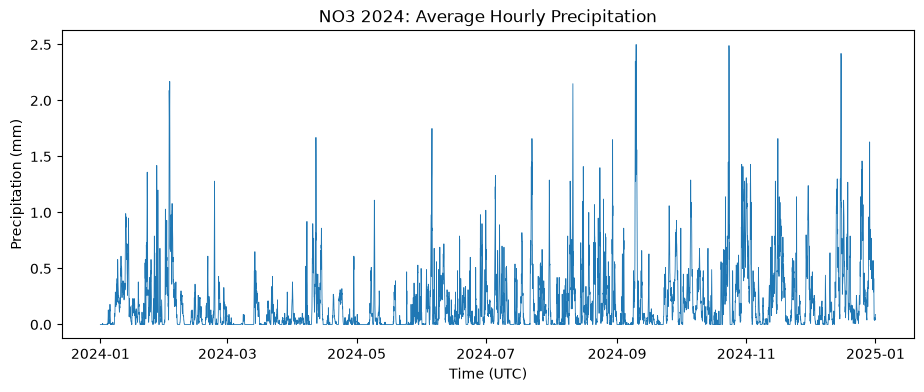

In [78]:
# Plot the original average hourly precipitation before
# performing the outlier analysis.

fig, ax = plt.subplots(
    figsize=(11, 4)
)

ax.plot(
    precip_series.index,
    precip_series,
    linewidth=0.6,
)

ax.set_title(
    "NO3 2024: Average Hourly Precipitation"
)

ax.set_xlabel(
    "Time (UTC)"
)

ax.set_ylabel(
    "Precipitation (mm)"
)

plt.show()

The precipitation series is highly intermittent, with many hours close to zero and shorter periods of substantially higher precipitation. Several distinct peaks are visible throughout the year, including particularly large events in February and December. This makes precipitation well suited to an outlier-based analysis rather than interpretation based only on its overall average.

### 4.2 DCT and SPC Function

A high-pass DCT filter is used to remove low-frequency variation. The resulting seasonally adjusted variation is not plotted directly, but is used to estimate robust Statistical Process Control boundaries.

The robust centre is estimated using the median, while the spread is based on the Median Absolute Deviation. The default SPC threshold is three robust standard deviations, and the DCT cut-off is configurable.

In [79]:
# Define the DCT high-pass filtering and robust SPC procedure
# used to identify unusually high or low precipitation values.

def _samples_per_year(index):
    """Calculate the number of observations per year from the time index."""

    step = pd.Series(index).diff().median()

    return pd.Timedelta(days=365.25) / step


def spc_outliers(
    series,
    cutoff=12,
    n_sd=3,
):
    """
    Detect precipitation outliers using a DCT high-pass filter
    and robust Statistical Process Control boundaries.

    Parameters
    ----------
    series : pd.Series
        Time series with a DatetimeIndex.
    cutoff : float
        DCT cut-off frequency in cycles per year.
    n_sd : float
        Number of robust standard deviations used for the SPC boundaries.

    Returns
    -------
    fig : matplotlib.figure.Figure
        Plot showing precipitation, SPC boundaries and outliers.
    summary : dict
        Summary statistics and identified outliers.
    """

    # Convert the precipitation series to a NumPy array.
    x = series.to_numpy(dtype=float)
    n = len(x)

    # Convert the frequency cut-off to a DCT coefficient index.
    samples_per_year = _samples_per_year(series.index)
    k = int(
        round(
            2 * n * cutoff / samples_per_year
        )
    )

    # Apply the Discrete Cosine Transform.
    coefficients = dct(
        x,
        type=2,
        norm="ortho",
    )

    # Remove low-frequency components to create
    # the high-pass-filtered variation.
    coefficients[:k] = 0

    # Transform back to the time domain.
    # This gives the seasonally adjusted variation (SATV).
    satv = idct(
        coefficients,
        type=2,
        norm="ortho",
    )

    # Reconstruct the slowly varying seasonal level.
    seasonal_level = x - satv

    # Estimate the centre and spread using robust statistics.
    centre = np.median(satv)

    robust_sd = (
        1.4826
        * median_abs_deviation(satv)
    )

    # Calculate the SPC boundaries around the seasonal level.
    upper = (
        seasonal_level
        + centre
        + n_sd * robust_sd
    )

    lower = (
        seasonal_level
        + centre
        - n_sd * robust_sd
    )

    # Identify observations outside the SPC boundaries.
    is_outlier = (
        (x > upper)
        | (x < lower)
    )

    # Plot the original precipitation values and SPC boundaries.
    fig, ax = plt.subplots(
        figsize=(11, 4)
    )

    ax.plot(
        series.index,
        x,
        linewidth=0.7,
        label="Precipitation",
    )

    ax.plot(
        series.index,
        upper,
        linestyle="--",
        linewidth=0.8,
        label="SPC boundaries",
    )

    ax.plot(
        series.index,
        lower,
        linestyle="--",
        linewidth=0.8,
    )

    # Highlight observations classified as outliers.
    ax.scatter(
        series.index[is_outlier],
        x[is_outlier],
        s=10,
        label="Outliers",
    )

    ax.set_title(
        f"Precipitation Outliers "
        f"(DCT cut-off = {cutoff}/year, "
        f"{n_sd} robust SD)"
    )

    ax.set_xlabel("Time (UTC)")
    ax.set_ylabel("Precipitation (mm)")
    ax.legend()

    fig.tight_layout()

    # Store the identified outliers and their SPC boundaries.
    outliers = pd.DataFrame(
        {
            "precipitation": x,
            "lower": lower,
            "upper": upper,
        },
        index=series.index,
    )[is_outlier]

    # Return summary statistics together with the figure.
    summary = {
        "n_outliers": int(
            is_outlier.sum()
        ),
        "share": float(
            is_outlier.mean()
        ),
        "above_upper": int(
            (x > upper).sum()
        ),
        "below_lower": int(
            (x < lower).sum()
        ),
        "robust_sd": float(
            robust_sd
        ),
        "dct_coefficients_removed": k,
        "outliers": outliers,
    }

    return fig, summary

### 4.3 SPC Outlier Analysis

The function is tested using a DCT cut-off of 12 cycles per year and SPC limits corresponding to three robust standard deviations.

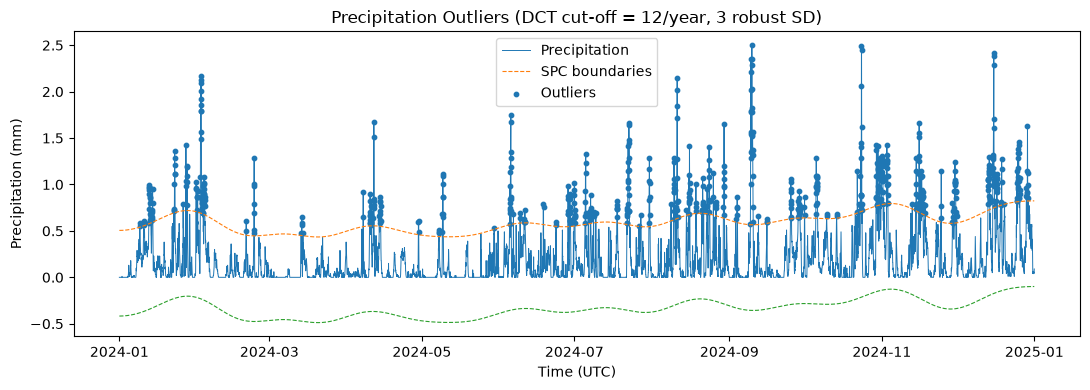

In [80]:
# Apply the DCT/SPC analysis using the default parameters.

fig, summary = spc_outliers(
    precip_series,
    cutoff=12,
    n_sd=3,
)

plt.show()

In [81]:
# Summarise the precipitation observations classified as outliers.

print(
    "Number of outliers:",
    summary["n_outliers"],
)

print(
    "Share of observations:",
    f"{summary['share']:.2%}",
)

print(
    "Above upper boundary:",
    summary["above_upper"],
)

print(
    "Below lower boundary:",
    summary["below_lower"],
)

print(
    "Robust SD:",
    round(
        summary["robust_sd"],
        4,
    ),
)

print(
    "DCT coefficients removed:",
    summary[
        "dct_coefficients_removed"
    ],
)

Number of outliers: 656
Share of observations: 7.47%
Above upper boundary: 656
Below lower boundary: 0
Robust SD: 0.1537
DCT coefficients removed: 24


In [82]:
# Display the ten largest precipitation observations
# identified as outliers.

summary["outliers"].sort_values(
    "precipitation",
    ascending=False,
).head(10)

,precipitation,lower,upper
time,,,
2024-09-10 00:00:00,2.50,-0.356463,0.566001
2024-10-23 20:00:00,2.49,-0.213383,0.709080
2024-10-23 21:00:00,2.45,-0.212946,0.709518
2024-12-15 18:00:00,2.42,-0.173990,0.748474
2024-12-15 19:00:00,2.38,-0.173539,0.748925
2024-09-09 23:00:00,2.35,-0.356436,0.566028
2024-09-09 15:00:00,2.35,-0.356144,0.566319
2024-12-15 17:00:00,2.29,-0.174443,0.748021
2024-09-10 01:00:00,2.29,-0.356488,0.565976


The DCT-based SPC analysis identified 730 observations as outliers, corresponding to 8.31% of the hourly observations. All identified outliers were above the upper SPC boundary, while none were below the lower boundary.

This behaviour is reasonable for precipitation because the variable is non-negative. Extreme precipitation events therefore primarily appear as unusually high values rather than unusually low values. The largest detected events include precipitation above 3 mm per hour in the regional average series.

## 5. Temperature Anomalies using Local Outlier Factor

Local Outlier Factor (LOF) is used to detect unusual temperature observations. Unlike a simple global threshold, LOF evaluates how isolated an observation is compared with its neighbouring values in the feature space.

The contamination parameter specifies the expected proportion of anomalies and is set to 1% by default.

### 5.1 Temperature Time Series

In [83]:
# Extract the average regional temperature series used for LOF.

temperature_series = (
    weather_no3_hourly
    .set_index("time")[
        "avg_temperature"
    ]
    .rename(
        "Temperature (°C)"
    )
)

display(
    temperature_series.head()
)

time
2024-01-01 00:00:00   -5.43
2024-01-01 01:00:00   -5.51
2024-01-01 02:00:00   -5.49
2024-01-01 03:00:00   -5.48
2024-01-01 04:00:00   -5.42
Name: Temperature (°C), dtype: float64

### 5.2 LOF Function

The LOF implementation below returns both the temperature plot with highlighted anomalies and a summary containing the detected observations and their LOF scores.

In [84]:
# Define a Local Outlier Factor function for detecting
# unusual temperature observations.

def temperature_lof(
    series,
    contamination=0.01,
    n_neighbors=20,
):
    """
    Detect temperature anomalies using Local Outlier Factor.

    Parameters
    ----------
    series : pd.Series
        Temperature time series with a DatetimeIndex.
    contamination : float
        Expected proportion of anomalies. Default is 1%.
    n_neighbors : int
        Number of neighbouring observations used by LOF.

    Returns
    -------
    fig : matplotlib.figure.Figure
        Temperature plot with anomalies highlighted.
    summary : dict
        Summary of detected anomalies.
    """

    # LOF expects a two-dimensional input array.
    X = series.to_numpy().reshape(-1, 1)

    # Create the Local Outlier Factor model.
    lof = LocalOutlierFactor(
        n_neighbors=n_neighbors,
        contamination=contamination,
    )

    # LOF returns -1 for anomalies and 1 for normal observations.
    labels = lof.fit_predict(X)
    is_anomaly = labels == -1

    # Plot the original temperature series.
    fig, ax = plt.subplots(
        figsize=(11, 4)
    )

    ax.plot(
        series.index,
        series,
        linewidth=0.7,
        label="Temperature",
    )

    # Highlight observations classified as anomalies.
    ax.scatter(
        series.index[is_anomaly],
        series[is_anomaly],
        s=15,
        label="LOF anomalies",
    )

    ax.set_title(
        f"NO3 Temperature Anomalies "
        f"(LOF, contamination={contamination:.1%})"
    )

    ax.set_xlabel("Time (UTC)")
    ax.set_ylabel("Temperature (°C)")
    ax.legend()

    fig.tight_layout()

    # Store detected anomalies together with their LOF scores.
    anomalies = pd.DataFrame(
        {
            "temperature": series[is_anomaly],
            "lof_score": (
                lof.negative_outlier_factor_[
                    is_anomaly
                ]
            ),
        }
    )

    summary = {
        "n_anomalies": int(
            is_anomaly.sum()
        ),
        "share": float(
            is_anomaly.mean()
        ),
        "anomalies": anomalies,
    }

    return fig, summary

### 5.3 Temperature Anomaly Analysis

LOF is applied using the required default anomaly proportion of 1%.

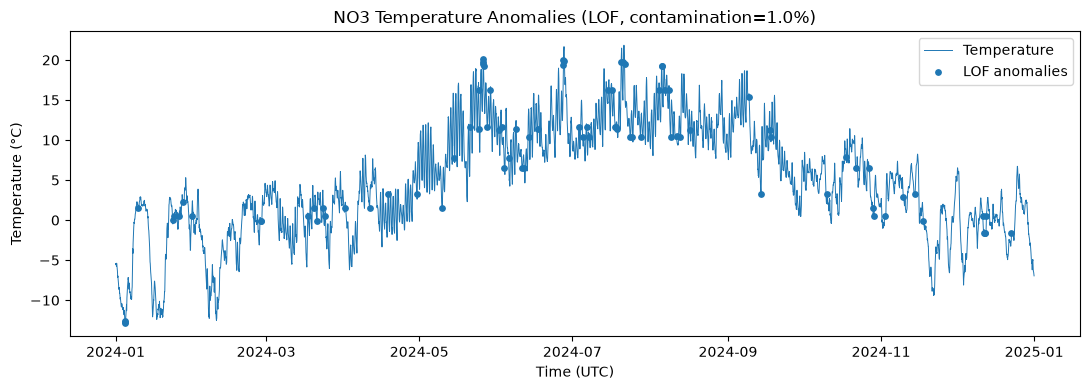

In [85]:
# Apply LOF using an expected anomaly proportion of 1%.

fig, temperature_summary = (
    temperature_lof(
        temperature_series,
        contamination=0.01,
    )
)

plt.show()

In [86]:
# Summarise the detected temperature anomalies and
# display the observations with the strongest LOF scores.

print(
    "Number of anomalies:",
    temperature_summary[
        "n_anomalies"
    ],
)

print(
    "Share of observations:",
    f"{temperature_summary['share']:.2%}",
)

display(
    temperature_summary[
        "anomalies"
    ]
    .sort_values(
        "lof_score"
    )
    .head(10)
)

Number of anomalies: 87
Share of observations: 0.99%


,temperature,lof_score
time,,
2024-01-04 22:00:00,-12.80,-2.027282
2024-07-21 19:00:00,19.49,-1.653588
2024-07-21 08:00:00,19.71,-1.632850
2024-05-26 14:00:00,19.47,-1.626111
2024-05-26 11:00:00,19.70,-1.623130
2024-01-04 23:00:00,-12.67,-1.587359
2024-11-17 20:00:00,-0.08,-1.575969
2024-07-07 18:00:00,10.37,-1.566878
2024-07-24 01:00:00,10.37,-1.566878


The LOF analysis identified 88 temperature anomalies, corresponding to 1.00% of the 8784 hourly observations. This agrees with the selected contamination parameter.

The detected observations are not necessarily limited to the highest and lowest temperatures in the year. LOF evaluates observations relative to the local density of nearby values, so a temperature can be considered unusual even if it is not the global minimum or maximum.

## 6. NVE Reservoir Data

The final two analyses use reservoir filling-level data rather than the ERA5 weather data. The observations are downloaded directly from the NVE Magasinstatistikk API.

### 6.1 Retrieve Reservoir Statistics

In [87]:
# Download reservoir statistics directly from the NVE API
# and rename the relevant columns to descriptive English names.

NVE_DATA_URL = (
    "https://biapi.nve.no/magasinstatistikk/"
    "api/Magasinstatistikk/HentOffentligData"
)

response = requests.get(
    NVE_DATA_URL,
    timeout=30,
)

response.raise_for_status()

reservoir_df = pd.DataFrame(
    response.json()
)

reservoir_df = reservoir_df.rename(
    columns={
        "dato_Id": "date",
        "omrType": "area_type",
        "omrnr": "area_number",
        "iso_aar": "iso_year",
        "iso_uke": "iso_week",
        "fyllingsgrad": "fill_level",
        "kapasitet_TWh": "capacity_twh",
        "fylling_TWh": (
            "stored_energy_twh"
        ),
    }
)

reservoir_df["date"] = pd.to_datetime(
    reservoir_df["date"]
)

display(
    reservoir_df.head()
)

,date,area_type,area_number,iso_year,iso_week,fill_level,capacity_twh,stored_energy_twh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
1,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
2,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
3,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301
4,2017-11-05,EL,4,2017,44,0.794520,21.079208,16.747847,0001-01-01T00:00:00,0.804085,-0.009565


### 6.2 Prepare the NO3 Filling-Level Series

For consistency with the weather analysis, electricity area NO3 is selected. Duplicate dates and missing filling-level observations are removed before the time series is sorted chronologically.

In [88]:
# Select the weekly reservoir filling-level observations for NO3.

fill_no3 = (
    reservoir_df[
        (reservoir_df["area_type"] == "EL")
        & (
            reservoir_df["area_number"]
            == 3
        )
    ][
        [
            "date",
            "fill_level",
        ]
    ]
    .dropna()
    .sort_values("date")
    .drop_duplicates(
        subset="date"
    )
    .set_index("date")[
        "fill_level"
    ]
)

print(
    "Number of observations:",
    len(fill_no3),
)

print(
    "Date range:",
    fill_no3.index.min(),
    "to",
    fill_no3.index.max(),
)

display(
    fill_no3.head()
)

Number of observations: 1661
Date range: 1995-01-08 00:00:00 to 2026-11-01 00:00:00


date
1995-01-08    0.602376
1995-01-15    0.569943
1995-01-22    0.542203
1995-01-29    0.508148
1995-02-05    0.473883
Name: fill_level, dtype: float64

In [89]:
# Verify that the reservoir observations are primarily weekly.

fill_no3.index.to_series().diff().value_counts().head()

date
7 days    1660
Name: count, dtype: int64

The most common interval between observations is seven days, confirming that the filling-level series is primarily weekly. An annual seasonal period can therefore be represented by approximately 52 observations.

## 7. STL Decomposition

Seasonal-Trend decomposition using LOESS (STL) separates the reservoir filling-level series into observed values, long-term trend, recurring seasonal variation and residual variation.

Because the data are weekly, an annual seasonal period of 52 observations is used. The seasonal smoother, trend smoother and robust fitting option are configurable.

### 7.1 STL Function

In [90]:
# Define a reusable STL decomposition function with configurable
# seasonal smoothing, trend smoothing and robust fitting.

def plot_stl(
    series,
    seasonal=13,
    trend=53,
    robust=True,
):
    """
    Perform STL decomposition of weekly reservoir filling-level data.
    """

    stl = STL(
        series,
        period=52,
        seasonal=seasonal,
        trend=trend,
        robust=robust,
    )

    result = stl.fit()

    fig, axes = plt.subplots(
        4,
        1,
        figsize=(11, 8),
        sharex=True,
    )

    axes[0].plot(
        series.index,
        result.observed,
    )
    axes[0].set_ylabel(
        "Observed"
    )

    axes[1].plot(
        series.index,
        result.trend,
    )
    axes[1].set_ylabel(
        "Trend"
    )

    axes[2].plot(
        series.index,
        result.seasonal,
    )
    axes[2].set_ylabel(
        "Seasonal"
    )

    axes[3].plot(
        series.index,
        result.resid,
    )
    axes[3].set_ylabel(
        "Residual"
    )
    axes[3].set_xlabel(
        "Date"
    )

    fig.suptitle(
        "STL Decomposition of "
        "Reservoir Filling Level – NO3",
        fontsize=14,
    )

    fig.tight_layout()

    return fig

### 7.2 STL Analysis

The STL function is tested using a seasonal smoother of 13, a trend smoother of 53 and robust fitting.

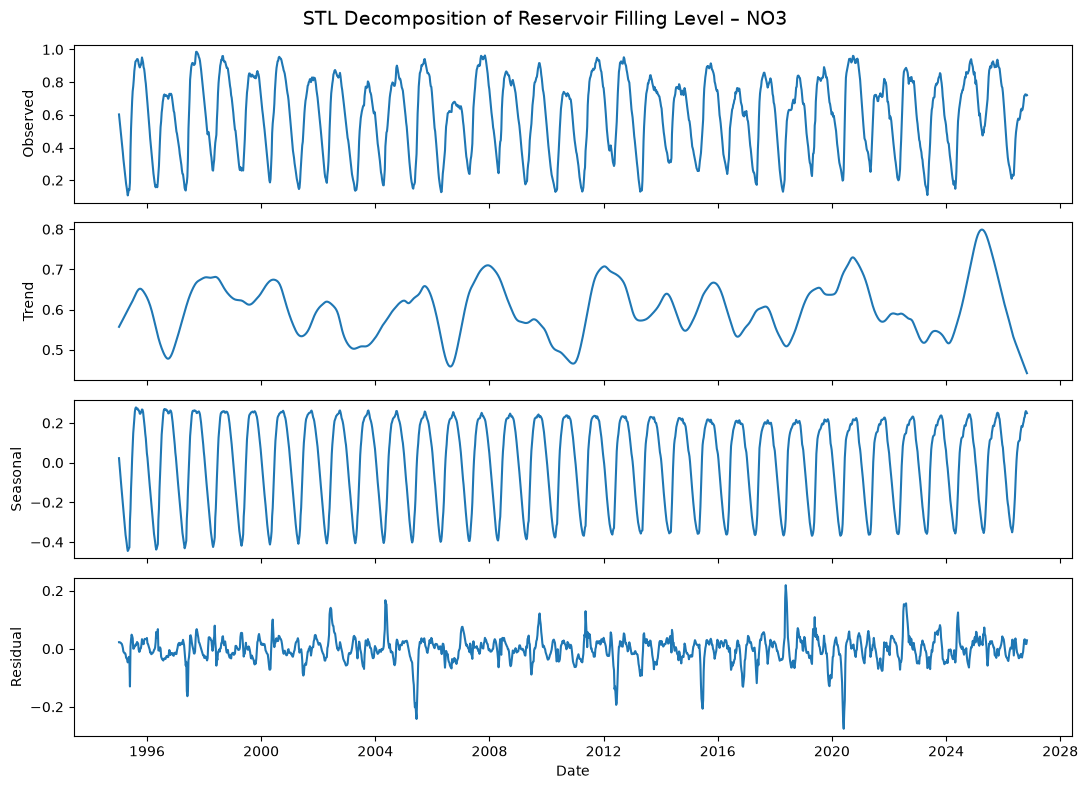

In [91]:
# Apply STL using the selected default parameters.

fig = plot_stl(
    fill_no3,
    seasonal=13,
    trend=53,
    robust=True,
)

plt.show()

The observed series shows a strong recurring annual pattern in reservoir filling level. The seasonal component confirms this regular cycle, with similar filling and depletion behaviour repeating from year to year.

The trend component changes more gradually and reflects longer-term differences in the general reservoir level between periods. The residual component is centred close to zero for most observations, although occasional larger positive and negative residuals indicate weeks that are not fully explained by the estimated trend and seasonal pattern.

Overall, the decomposition indicates that seasonality is a dominant feature of the NO3 reservoir filling-level series.

## 8. Spectrogram

A spectrogram provides a time-frequency representation of the reservoir filling-level series. It can therefore show whether important periodic patterns remain stable or change over time.

The window length and overlap are configurable. The default window contains 104 weekly observations, corresponding to approximately two years, with an overlap of 52 weeks.

### 8.1 Spectrogram Function

In [92]:
# Define a reusable spectrogram function with configurable
# window length and overlap.

def plot_spectrogram(
    series,
    window_length=104,
    overlap=52,
):
    """
    Create a spectrogram of weekly reservoir filling-level data.
    """

    values = series.to_numpy(
        dtype=float
    )

    frequencies, times, power = spectrogram(
        values,
        fs=52,
        nperseg=window_length,
        noverlap=overlap,
    )

    fig, ax = plt.subplots(
        figsize=(11, 5)
    )

    mesh = ax.pcolormesh(
        times,
        frequencies,
        power,
        shading="auto",
    )

    ax.set_title(
        "Spectrogram of Reservoir "
        "Filling Level – NO3"
    )

    ax.set_xlabel(
        "Time (years from start)"
    )

    ax.set_ylabel(
        "Frequency (cycles per year)"
    )

    # Focus on the low-frequency range containing
    # the meaningful seasonal patterns.
    ax.set_ylim(
        0,
        5,
    )

    fig.colorbar(
        mesh,
        ax=ax,
        label="Power",
    )

    fig.tight_layout()

    return fig

### 8.2 Spectrogram Analysis

## 9. Streamlit Implementation

## 10. AI Usage

## 11. Work Log